# Búsquedas de 4 películas y un meme (Google Trends)

**Pregunta:** ¿cuánto se buscó cada tema por día, y cuáles subieron y bajaron juntos?

**Temas:** *A Minecraft Movie*, *Chicken Jockey*, *Lilo & Stitch* y *Cómo entrenar a tu dragón*.

**Por qué se pueden comparar:** los cuatro temas salen de una sola descarga, así que sus números están en la misma escala (de 0 a 100). Igual que antes, el 100 es el día con más búsquedas de cada tema dentro de esa descarga. No sirve para comparar con otra descarga hecha en otra fecha.

**Período del archivo:** el archivo tiene datos del 1 de enero al 30 de junio de **2026**. El rango que usamos está en la primera parte del notebook.

## 1. Preparación

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Donde esta el archivo
RUTA = "../data/raw/tendencias_4_peliculas_2025-01-01_2025-06-30.csv"

# Periodo a mirar (ano-mes-dia).
# Si lo dejas en None, se usan todas las fechas del archivo.
INICIO = None
FIN = None

## 2. Abrir el archivo

In [2]:
# Las dos primeras lineas del archivo no son datos, por eso las salteamos
raw = pd.read_csv(RUTA, skiprows=2)
print("Filas en el archivo:", len(raw))
raw.head()

Filas en el archivo: 181


,Día,Una película de Minecraft: (Todo el mundo),Chicken Jockey: (Todo el mundo),Lilo & Stitch: (Todo el mundo),Cómo entrenar a tu dragón: (Todo el mundo)
0,2025-01-01,1,0,<1,1
1,2025-01-02,1,0,<1,1
2,2025-01-03,1,0,<1,<1
3,2025-01-04,1,0,<1,1
4,2025-01-05,1,0,<1,1


In [3]:
# Google Trends a veces pone "<1" cuando el numero es muy chico.
# Lo cambiamos por 0.5 y convertimos toda la columna a numeros.
def limpiar(columna):
    lista = [0.5 if str(v).strip() == "<1" else v for v in columna]
    return pd.to_numeric(lista, errors="coerce")

# Ordenar la tabla con nombres cortos y el dia como titulo de cada fila
df = pd.DataFrame(
    {
        "Minecraft": limpiar(raw.iloc[:, 1].values),
        "Chicken Jockey": limpiar(raw.iloc[:, 2].values),
        "Lilo & Stitch": limpiar(raw.iloc[:, 3].values),
        "Cómo entrenar a tu dragón": limpiar(raw.iloc[:, 4].values),
    },
    index=raw["Día"].values,
)

print("El archivo tiene datos desde", raw["Día"].min(), "hasta", raw["Día"].max())

# Quedarnos solo con el periodo elegido (si se pusieron fechas)
if INICIO is not None:
    df = df[df.index >= INICIO]
if FIN is not None:
    df = df[df.index <= FIN]

print("Datos vacíos:", df.isnull().sum().sum())
print(f"Días que vamos a mirar: {len(df)}")
print("Tipo de dato de cada columna:")
print(df.dtypes)
df.head()

El archivo tiene datos desde 2025-01-01 hasta 2025-06-30
Datos vacíos: 0
Días que vamos a mirar: 181
Tipo de dato de cada columna:
Minecraft                      int64
Chicken Jockey               float64
Lilo & Stitch                float64
Cómo entrenar a tu dragón    float64
dtype: object


,Minecraft,Chicken Jockey,Lilo & Stitch,Cómo entrenar a tu dragón
2025-01-01,1,0.0,0.5,1.0
2025-01-02,1,0.0,0.5,1.0
2025-01-03,1,0.0,0.5,0.5
2025-01-04,1,0.0,0.5,1.0
2025-01-05,1,0.0,0.5,1.0


## 3. Números generales

In [4]:
df.describe().round(1)

,Minecraft,Chicken Jockey,Lilo & Stitch,Cómo entrenar a tu dragón
count,181.0,181.0,181.0,181.0
mean,8.8,0.9,4.7,3.4
std,14.6,1.2,8.4,5.7
min,1.0,0.0,0.5,0.5
25%,1.0,0.0,0.5,1.0
50%,4.0,0.5,1.0,1.0
75%,8.0,1.0,5.0,2.0
max,100.0,6.0,49.0,34.0


## 4. Gráfico de los cuatro temas

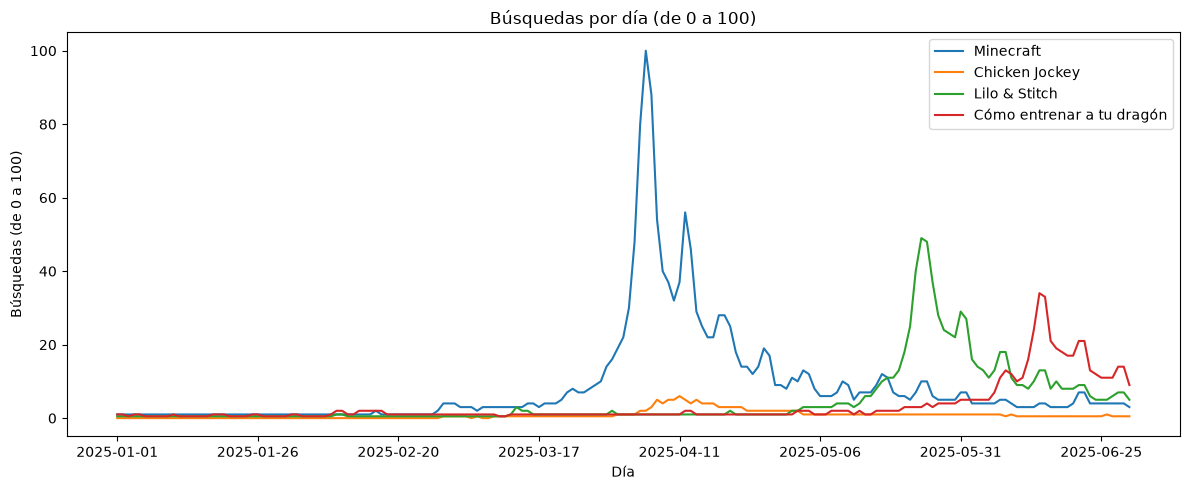

In [5]:
ax = df.plot(figsize=(12, 5), title="Búsquedas por día (de 0 a 100)")
ax.set_xlabel("Día")
ax.set_ylabel("Búsquedas (de 0 a 100)")
plt.tight_layout()
plt.show()

## 5. Punto más alto de cada tema

In [6]:
for tema in df.columns:
    punto_mas_alto = df[tema].max()
    dia = df[df[tema] == punto_mas_alto].index[0]
    print(f"{tema}: su punto más alto fue {punto_mas_alto} el día {dia}")

Minecraft: su punto más alto fue 100 el día 2025-04-05
Chicken Jockey: su punto más alto fue 6.0 el día 2025-04-11
Lilo & Stitch: su punto más alto fue 49.0 el día 2025-05-24
Cómo entrenar a tu dragón: su punto más alto fue 34.0 el día 2025-06-14


## 6. Promedio de cada tema

In [7]:
promedio = df.mean().round(1)
print("Promedio diario de cada tema:")
print(promedio)

Promedio diario de cada tema:
Minecraft                    8.8
Chicken Jockey               0.9
Lilo & Stitch                4.7
Cómo entrenar a tu dragón    3.4
dtype: float64


In [8]:
# Cuantas veces mas (o menos) se busca cada tema, comparado con Minecraft
print("Comparado con Minecraft (1 = igual):")
for tema in df.columns:
    print(f"{tema}: {promedio[tema] / promedio['Minecraft']:.2f}")

Comparado con Minecraft (1 = igual):
Minecraft: 1.00
Chicken Jockey: 0.10
Lilo & Stitch: 0.53
Cómo entrenar a tu dragón: 0.39


## 7. ¿Qué temas suben y bajan juntos?

In [9]:
# Cerca de 1: suben y bajan casi igual.
# Cerca de 0: no tienen nada que ver entre si.
df.corr().round(2)

,Minecraft,Chicken Jockey,Lilo & Stitch,Cómo entrenar a tu dragón
Minecraft,1.00,0.70,-0.07,-0.12
Chicken Jockey,0.70,1.00,0.02,-0.08
Lilo & Stitch,-0.07,0.02,1.00,0.33
Cómo entrenar a tu dragón,-0.12,-0.08,0.33,1.00


Un número cerca de 1 quiere decir que dos temas suben y bajan casi igual. Un número cerca de 0 quiere decir que no tienen nada que ver. Este análisis mira días, pero no dice por qué pasa cada cosa.

## 8. Qué podemos decir

**Lo que muestran los datos del archivo que usamos (enero a junio de 2026).** Si cambiás por otro archivo o período, revisá estas frases:

- *Cómo entrenar a tu dragón* es el tema que más se busca. Su promedio diario es unas 1,5 veces el de *A Minecraft Movie*.
- *Chicken Jockey* casi no se busca. Su promedio es muy bajo y nunca supera 4.
- *Lilo & Stitch* tiene un pico muy grande un día de junio. Fuera de ese día, se busca menos que *Cómo entrenar a tu dragón*.
- *A Minecraft Movie* y *Cómo entrenar a tu dragón* son los dos temas que más se parecen en cómo suben y bajan.

**Lo que no podemos decir:**

- Por qué pasó cada pico. Los datos muestran cuándo, pero no el motivo.
- Cómo se compara esto con 2025. Para eso hace falta el archivo del primer semestre de 2025, con sus datos cargados en el mismo notebook.